[-2.         -1.8        -1.6        -1.4        -1.2        -1.
 -0.8        -0.6        -0.4        -0.2         0.          0.15789474
  0.31578947  0.47368421  0.63157895  0.78947368  0.94736842  1.10526316
  1.26315789  1.42105263  1.57894737  1.73684211  1.89473684  2.05263158
  2.21052632  2.36842105  2.52631579  2.68421053  2.84210526  3.        ]
e^ -2.0  =  0.13533528323661267 (近似值)	 0.1353352832366127 (真实值)
e^ -1.8  =  0.16529888822158215 (近似值)	 0.16529888822158653 (真实值)
e^ -1.6  =  0.20189651799465555 (近似值)	 0.20189651799465538 (真实值)
e^ -1.4  =  0.2465969639416065 (近似值)	 0.2465969639416065 (真实值)
e^ -1.2  =  0.301194211912202 (近似值)	 0.30119421191220214 (真实值)
e^ -1.0  =  0.36787944117145815 (近似值)	 0.36787944117144233 (真实值)
e^ -0.7999999999999998  =  0.4493289641172216 (近似值)	 0.4493289641172217 (真实值)
e^ -0.5999999999999999  =  0.5488116360940265 (近似值)	 0.5488116360940265 (真实值)
e^ -0.3999999999999999  =  0.6703200460356091 (近似值)	 0.6703200460356393 (真实值)
e^ -0.19999999999999996

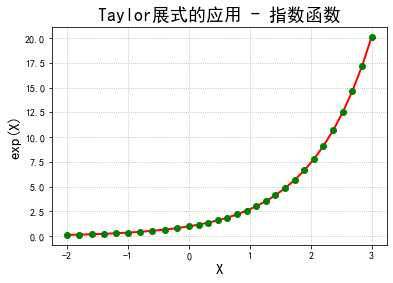

In [5]:
#Taylor 展开的 近似逼近
import numpy as np
import math
import matplotlib as mpl
import matplotlib.pyplot as plt

#计算
def calc_e_small(x):
    n = 10
    f = np.arange(1, n+1).cumprod()
    b = np.array([x]*n).cumprod()
    return np.sum(b / f) + 1

#计算e^x
def calc_e(x):
    reverse = False
    if x < 0:   # 处理负数
        x = -x
        reverse = True
    ln2 = 0.69314718055994530941723212145818
    c = x / ln2
    a = int(c+0.5)
    b = x - a*ln2
    y = (2 ** a) * calc_e_small(b)
    if reverse:
        return 1/y
    return y


if __name__ == "__main__":
    t1 = np.linspace(-2, 0, 10, endpoint=False)
    t2 = np.linspace(0, 3, 20)
    t = np.concatenate((t1, t2))
    print(t)     # 横轴数据
    y = np.empty_like(t)
    for i, x in enumerate(t):
        y[i] = calc_e(x)
        print('e^', x, ' = ', y[i], '(近似值)\t', math.exp(x), '(真实值)')
        # print '误差：', y[i] - math.exp(x)
    plt.figure(facecolor='w')
    mpl.rcParams['font.sans-serif'] = [u'SimHei']
    mpl.rcParams['axes.unicode_minus'] = False
    plt.plot(t, y, 'r-', t, y, 'go', linewidth=2)
    plt.title(u'Taylor展式的应用 - 指数函数', fontsize=18)
    plt.xlabel('X', fontsize=15)
    plt.ylabel('exp(X)', fontsize=15)
    plt.grid(True, ls=':')
    plt.show()


In [16]:
def calc_e_small(x):
    n = 10
    f = np.arange(1, n+1).cumprod()
    b = np.array([x]*n).cumprod()
    return b/f

r = 1.0
for i in range(1,11):
    r = r + calc_e_small(3)

print(r)

[31.         46.         46.         34.75       21.25       11.125
  5.33928571  2.62723214  1.54241071  1.16272321]


In [22]:

def calc_e_small(x):
    n = 10
    f = np.arange(1, n+1).cumprod()
    b = np.array([x]*n).cumprod()
    return np.sum(b / f) + 1

print(calc_e_small(3))

print(math.exp(3))
print(np.log1p(2))

20.079665178571425
20.085536923187668
1.0986122886681098


In [24]:
#!/usr/bin/python
#  -*- coding:utf-8 -*-


class People:
    def __init__(self, n, a, s):
        self.name = n
        self.age = a
        self.__score = s
        self.print_people()
        # self.__print_people()   # 私有函数的作用

    def print_people(self):
        str = u'%s的年龄：%d，成绩为：%.2f' % (self.name, self.age, self.__score)
        print(str)

    __print_people = print_people


class Student(People):
    def __init__(self, n, a, w):
        People.__init__(self, n, a, w)
        self.name = 'Student ' + self.name

    def print_people(self):
        str = u'%s的年龄：%d' % (self.name, self.age)
        print(str)


def func(p):
    p.age = 11


if __name__ == '__main__':
    p = People('Tom', 10, 3.14159)
    func(p)     # p传入的是引用类型
    p.print_people()
    print()

    # 注意分析下面语句的打印结果，是否觉得有些“怪异”？
    j = Student('Jerry', 12, 2.71828)
    print()

    # 成员函数
    p.print_people()
    j.print_people()
    print()

    People.print_people(p)
    People.print_people(j)


Tom的年龄：10，成绩为：3.14
Tom的年龄：11，成绩为：3.14

Jerry的年龄：12

Tom的年龄：11，成绩为：3.14
Student Jerry的年龄：12

Tom的年龄：11，成绩为：3.14
Student Jerry的年龄：12，成绩为：2.72


In [25]:
np.arange(1, 10+1).cumprod()

array([      1,       2,       6,      24,     120,     720,    5040,
         40320,  362880, 3628800], dtype=int32)

        TV  Radio  Newspaper
0    230.1   37.8       69.2
1     44.5   39.3       45.1
2     17.2   45.9       69.3
3    151.5   41.3       58.5
4    180.8   10.8       58.4
..     ...    ...        ...
195   38.2    3.7       13.8
196   94.2    4.9        8.1
197  177.0    9.3        6.4
198  283.6   42.0       66.2
199  232.1    8.6        8.7

[200 rows x 3 columns]
0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: Sales, Length: 200, dtype: float64
超参数：
 {'alpha': 0.5994842503189409}
0.9147734784738105
1.992871866305969 1.4116911370076561


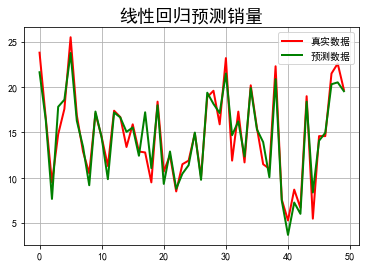

In [29]:
#!/usr/bin/python
# -*- coding:utf-8 -*-

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV


if __name__ == "__main__":
    # pandas读入
    data = pd.read_csv('D:/pyprj/python高级/机器学习-邹博/文档/10.Regression/10.Advertising.csv')    # TV、Radio、Newspaper、Sales
    x = data[['TV', 'Radio', 'Newspaper']]
    # x = data[['TV', 'Radio']]
    y = data['Sales']
    print (x)
    print (y)

    x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=1)
    model = Lasso()
    # model = Ridge()
    alpha_can = np.logspace(-3, 2, 10)
    lasso_model = GridSearchCV(model, param_grid={'alpha': alpha_can}, cv=5)
    lasso_model.fit(x_train, y_train)
    print('超参数：\n', lasso_model.best_params_)

    y_hat = lasso_model.predict(np.array(x_test))
    print (lasso_model.score(x_test, y_test))
    mse = np.average((y_hat - np.array(y_test)) ** 2)  # Mean Squared Error
    rmse = np.sqrt(mse)  # Root Mean Squared Error
    print(mse, rmse )

    t = np.arange(len(x_test))
    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    plt.plot(t, y_test, 'r-', linewidth=2, label=u'真实数据')
    plt.plot(t, y_hat, 'g-', linewidth=2, label=u'预测数据')
    plt.title(u'线性回归预测销量', fontsize=18)
    plt.legend(loc='upper right')
    plt.grid()
    plt.show()


线性回归：1阶，系数为： [-12.12113792   3.05477422]
线性回归：2阶，系数为： [-3.23812184 -3.36390661  0.90493645]
线性回归：3阶，系数为： [-3.90207326 -2.61163034  0.66422328  0.02290431]
线性回归：4阶，系数为： [-8.20599769  4.20778207 -2.85304163  0.73902338 -0.05008557]
线性回归：5阶，系数为： [ 21.59733285 -54.12232017  38.43116219 -12.68651476   1.98134176  -0.11572371]
线性回归：6阶，系数为： [ 14.73304784 -37.87317493  23.67462341  -6.07037979   0.42536833   0.06803132  -0.00859246]
线性回归：7阶，系数为： [ 314.30344773 -827.89447315  857.33293588 -465.46543853  144.21883915  -25.67294689    2.44658613   -0.09675941]
线性回归：8阶，系数为： [-1189.50153102  3643.69120868 -4647.92955082  3217.22824022 -1325.8738807    334.32869995   -50.57119257     4.21251829    -0.14852101]
Ridge回归：1阶，alpha=0.109854，系数为： [-11.21592213   2.85121516]
Ridge回归：2阶，alpha=0.138950，系数为： [-2.90423989 -3.49931368  0.91803171]
Ridge回归：3阶，alpha=0.068665，系数为： [-3.47165245 -2.85078293  0.69245987  0.02314415]
Ridge回归：4阶，alpha=0.222300，系数为： [-2.84560266 -1.99887417 -0.40628792  0.33863868 -0.02

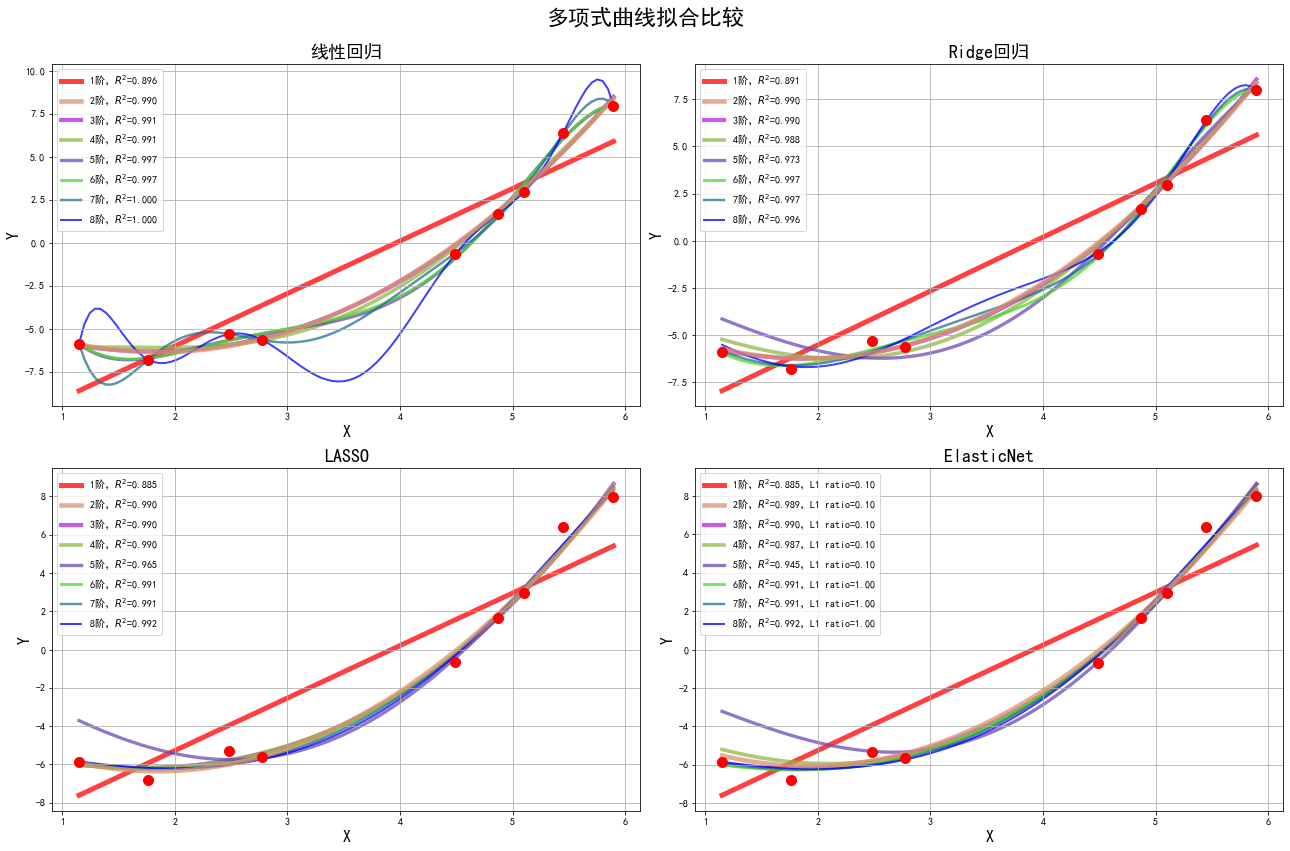

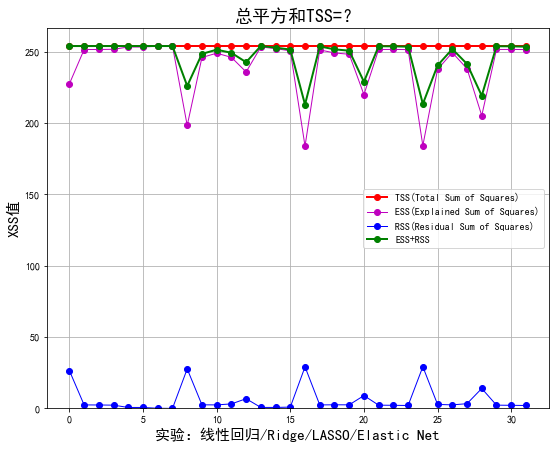

In [40]:
#!/usr/bin/python
# -*- coding:utf-8 -*-

import numpy as np
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.preprocessing import PolynomialFeatures
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
import matplotlib as mpl
import warnings

def xss(y, y_hat):
    y = y.ravel()
    y_hat = y_hat.ravel()
    # Version 1
    tss = ((y - np.average(y)) ** 2).sum()
    rss = ((y_hat - y) ** 2).sum()
    ess = ((y_hat - np.average(y)) ** 2).sum()
    r2 = 1 - rss / tss
    # print 'RSS:', rss, '\t ESS:', ess
    # print 'TSS:', tss, 'RSS + ESS = ', rss + ess
    tss_list.append(tss)
    rss_list.append(rss)
    ess_list.append(ess)
    ess_rss_list.append(rss + ess)
    # Version 2
    # tss = np.var(y)
    # rss = np.average((y_hat - y) ** 2)
    # r2 = 1 - rss / tss
    corr_coef = np.corrcoef(y, y_hat)[0, 1]
    return r2, corr_coef


if __name__ == "__main__":
    warnings.filterwarnings("ignore")   # ConvergenceWarning
    np.random.seed(0)
    np.set_printoptions(linewidth=1000)
    N = 9
    x = np.linspace(0, 6, N) + np.random.randn(N)
    x = np.sort(x)
    y = x**2 - 4*x - 3 + np.random.randn(N)
    x.shape = -1, 1
    y.shape = -1, 1

    models = [Pipeline([
        ('poly', PolynomialFeatures()),
        ('linear', LinearRegression(fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', RidgeCV(alphas=np.logspace(-3, 2, 50), fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', LassoCV(alphas=np.logspace(-3, 2, 50), fit_intercept=False))]),
        Pipeline([
            ('poly', PolynomialFeatures()),
            ('linear', ElasticNetCV(alphas=np.logspace(-3, 2, 50), l1_ratio=[.1, .5, .7, .9, .95, .99, 1],
                                    fit_intercept=False))])
    ]
    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    np.set_printoptions(suppress=True)

    plt.figure(figsize=(18, 12), facecolor='w')
    d_pool = np.arange(1, N, 1)  # 阶
    m = d_pool.size
    clrs = []  # 颜色
    for c in np.linspace(16711680, 255, m):
        clrs.append('#%06x' % np.int(c) )
    line_width = np.linspace(5, 2, m)
    titles = u'线性回归', u'Ridge回归', u'LASSO', u'ElasticNet'
    tss_list = []
    rss_list = []
    ess_list = []
    ess_rss_list = []
    for t in range(4):
        model = models[t]
        plt.subplot(2, 2, t+1)
        plt.plot(x, y, 'ro', ms=10, zorder=N)
        for i, d in enumerate(d_pool):
            model.set_params(poly__degree=d)
            model.fit(x, y.ravel())
            lin = model.get_params('linear')['linear']
            output = u'%s：%d阶，系数为：' % (titles[t], d)
            if hasattr(lin, 'alpha_'):
                idx = output.find(u'系数')
                output = output[:idx] + (u'alpha=%.6f，' % lin.alpha_) + output[idx:]
            if hasattr(lin, 'l1_ratio_'):   # 根据交叉验证结果，从输入l1_ratio(list)中选择的最优l1_ratio_(float)
                idx = output.find(u'系数')
                output = output[:idx] + (u'l1_ratio=%.6f，' % lin.l1_ratio_) + output[idx:]
            print (output, lin.coef_.ravel())
            x_hat = np.linspace(x.min(), x.max(), num=100)
            x_hat.shape = -1, 1
            y_hat = model.predict(x_hat)
            s = model.score(x, y)
            r2, corr_coef = xss(y, model.predict(x))
            # print 'R2和相关系数：', r2, corr_coef
            # print 'R2：', s, '\n'
            z = N - 1 if (d == 2) else 0
            label = u'%d阶，$R^2$=%.3f' % (d, s)
            if hasattr(lin, 'l1_ratio_'):
                label += u'，L1 ratio=%.2f' % lin.l1_ratio_
            plt.plot(x_hat, y_hat, color=clrs[i], lw=line_width[i], alpha=0.75, label=label, zorder=z)
        plt.legend(loc='upper left')
        plt.grid(True)
        plt.title(titles[t], fontsize=18)
        plt.xlabel('X', fontsize=16)
        plt.ylabel('Y', fontsize=16)
    plt.tight_layout(1, rect=(0, 0, 1, 0.95))
    plt.suptitle(u'多项式曲线拟合比较', fontsize=22)
    plt.show()

    y_max = max(max(tss_list), max(ess_rss_list)) * 1.05
    plt.figure(figsize=(9, 7), facecolor='w')
    t = np.arange(len(tss_list))
    plt.plot(t, tss_list, 'ro-', lw=2, label=u'TSS(Total Sum of Squares)')
    plt.plot(t, ess_list, 'mo-', lw=1, label=u'ESS(Explained Sum of Squares)')
    plt.plot(t, rss_list, 'bo-', lw=1, label=u'RSS(Residual Sum of Squares)')
    plt.plot(t, ess_rss_list, 'go-', lw=2, label=u'ESS+RSS')
    plt.ylim((0, y_max))
    plt.legend(loc='center right')
    plt.xlabel(u'实验：线性回归/Ridge/LASSO/Elastic Net', fontsize=15)
    plt.ylabel(u'XSS值', fontsize=15)
    plt.title(u'总平方和TSS=？', fontsize=18)
    plt.grid(True)
    plt.show()


In [39]:
c = np.linspace(16711680, 255, m)
'#%06x' % np.int(c)

TypeError: only size-1 arrays can be converted to Python scalars

        TV  Radio  Newspaper
0    230.1   37.8       69.2
1     44.5   39.3       45.1
2     17.2   45.9       69.3
3    151.5   41.3       58.5
4    180.8   10.8       58.4
..     ...    ...        ...
195   38.2    3.7       13.8
196   94.2    4.9        8.1
197  177.0    9.3        6.4
198  283.6   42.0       66.2
199  232.1    8.6        8.7

[200 rows x 3 columns]
0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: Sales, Length: 200, dtype: float64
超参数：
 {'alpha': 0.5994842503189409}
0.9147734784738105
1.992871866305969 1.4116911370076561


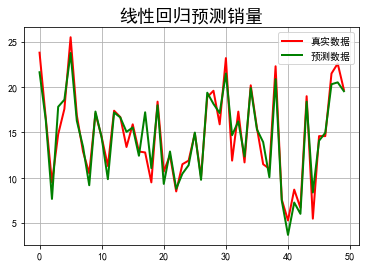

In [43]:
#!/usr/bin/python
# -*- coding:utf-8 -*-

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import GridSearchCV


if __name__ == "__main__":
    # pandas读入
    data = pd.read_csv('D:/pyprj/python高级/机器学习-邹博/文档/10.Regression/10.Advertising.csv')    # TV、Radio、Newspaper、Sales
    x = data[['TV', 'Radio', 'Newspaper']]
    # x = data[['TV', 'Radio']]
    y = data['Sales']
    print (x)
    print (y)

    x_train, x_test, y_train, y_test = train_test_split(x, y, random_state=1)
    model = Lasso()
    # model = Ridge()
    alpha_can = np.logspace(-3, 2, 10)
    lasso_model = GridSearchCV(model, param_grid={'alpha': alpha_can}, cv=5)
    lasso_model.fit(x_train, y_train)
    print ('超参数：\n', lasso_model.best_params_)

    y_hat = lasso_model.predict(np.array(x_test))
    print (lasso_model.score(x_test, y_test))
    mse = np.average((y_hat - np.array(y_test)) ** 2)  # Mean Squared Error
    rmse = np.sqrt(mse)  # Root Mean Squared Error
    print (mse, rmse)

    t = np.arange(len(x_test))
    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False
    plt.plot(t, y_test, 'r-', linewidth=2, label=u'真实数据')
    plt.plot(t, y_hat, 'g-', linewidth=2, label=u'预测数据')
    plt.title(u'线性回归预测销量', fontsize=18)
    plt.legend(loc='upper right')
    plt.grid()
    plt.show()


        TV  Radio
0    230.1   37.8
1     44.5   39.3
2     17.2   45.9
3    151.5   41.3
4    180.8   10.8
..     ...    ...
195   38.2    3.7
196   94.2    4.9
197  177.0    9.3
198  283.6   42.0
199  232.1    8.6

[200 rows x 2 columns]
0      22.1
1      10.4
2       9.3
3      18.5
4      12.9
       ... 
195     7.6
196     9.7
197    12.8
198    25.5
199    13.4
Name: Sales, Length: 200, dtype: float64


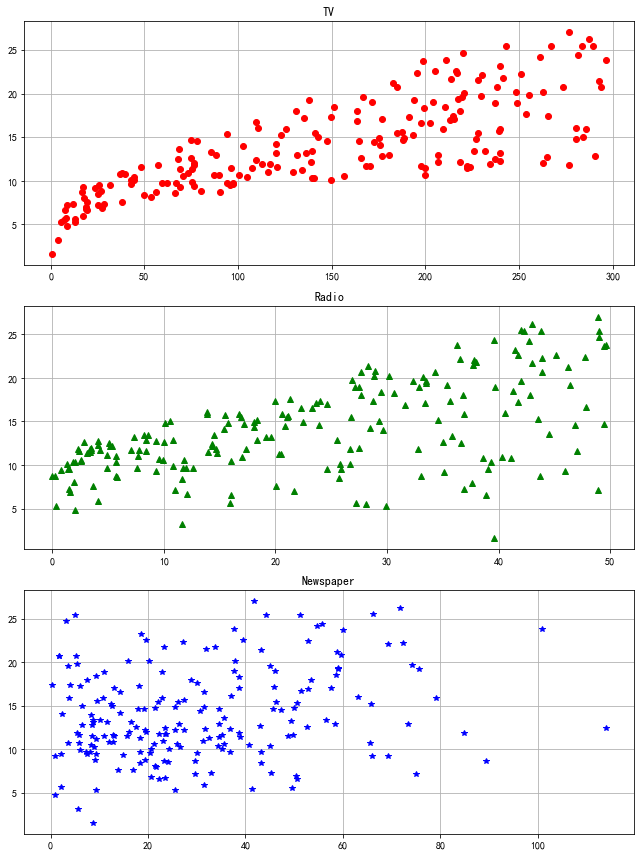

LinearRegression()
[0.04686997 0.1800065 ]
2.9475150360290012
1.955221885011318 1.3982924890777746


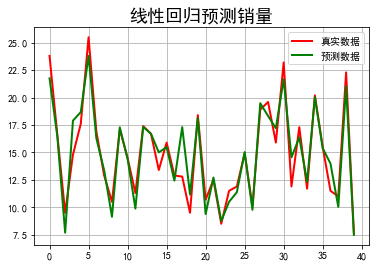

In [46]:
#!/usr/bin/python
# -*- coding:utf-8 -*-

import csv
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from pprint import pprint


if __name__ == "__main__":
    path = 'D:/pyprj/python高级/机器学习-邹博/文档/10.Regression/10.Advertising.csv'
    # # 手写读取数据 - 请自行分析，在10.2.Iris代码中给出类似的例子
    # f = file(path)
    # x = []
    # y = []
    # for i, d in enumerate(f):
    #     if i == 0:
    #         continue
    #     d = d.strip()
    #     if not d:
    #         continue
    #     d = map(float, d.split(','))
    #     x.append(d[1:-1])
    #     y.append(d[-1])
    # pprint(x)
    # pprint(y)
    # x = np.array(x)
    # y = np.array(y)

    # # Python自带库
    # f = file(path, 'rb')
    # print f
    # d = csv.reader(f)
    # for line in d:
    #     print line
    # f.close()

    # # numpy读入
    # p = np.loadtxt(path, delimiter=',', skiprows=1)
    # print p
    # print '\n\n===============\n\n'

    # pandas读入
    data = pd.read_csv(path)    # TV、Radio、Newspaper、Sales
    # x = data[['TV', 'Radio', 'Newspaper']]
    x = data[['TV', 'Radio']]
    y = data['Sales']
    print (x)
    print (y)

    mpl.rcParams['font.sans-serif'] = [u'simHei']
    mpl.rcParams['axes.unicode_minus'] = False

    # # 绘制1
    # plt.plot(data['TV'], y, 'ro', label='TV')
    # plt.plot(data['Radio'], y, 'g^', label='Radio')
    # plt.plot(data['Newspaper'], y, 'mv', label='Newspaer')
    # plt.legend(loc='lower right')
    # plt.grid()
    # plt.show()
    # #
    # 绘制2
    plt.figure(figsize=(9,12))
    plt.subplot(311)
    plt.plot(data['TV'], y, 'ro')
    plt.title('TV')
    plt.grid()
    plt.subplot(312)
    plt.plot(data['Radio'], y, 'g^')
    plt.title('Radio')
    plt.grid()
    plt.subplot(313)
    plt.plot(data['Newspaper'], y, 'b*')
    plt.title('Newspaper')
    plt.grid()
    plt.tight_layout()
    plt.show()

    x_train, x_test, y_train, y_test = train_test_split(x, y, train_size=0.8, random_state=1)
    # print x_train, y_train
    linreg = LinearRegression()
    model = linreg.fit(x_train, y_train)
    print (model)
    print (linreg.coef_)
    print (linreg.intercept_)

    y_hat = linreg.predict(np.array(x_test))
    mse = np.average((y_hat - np.array(y_test)) ** 2)  # Mean Squared Error
    rmse = np.sqrt(mse)  # Root Mean Squared Error
    print (mse, rmse)

    t = np.arange(len(x_test))
    plt.plot(t, y_test, 'r-', linewidth=2, label=u'真实数据')
    plt.plot(t, y_hat, 'g-', linewidth=2, label=u'预测数据')
    plt.legend(loc='upper right')
    plt.title(u'线性回归预测销量', fontsize=18)
    plt.grid()
    plt.show()
